# Bài 21: Đưa Mô hình vào Chương trình Thực tế — Inference Pipeline, Xuất Model (TorchScript/ONNX) và Tối ưu hóa

## 1. Mục tiêu học tập
- Hiểu cách đóng gói một mô hình đã huấn luyện thành **chương trình suy luận độc lập (`Production Inference Class`)**:
  - Lưu trữ đầy đủ `model_state_dict`, `class_names`, `class_to_idx`, `idx_to_class` và `preprocessing_config` (`image_size`, `mean`, `std`, `color_space='RGB'`) vào cùng 1 file `checkpoint`.
  - Tiền xử lý ảnh đầu vào khớp tuyệt đối với lúc huấn luyện (`BGR -> RGB`, `Resize`, `HWC uint8 -> NCHW float32`, `Normalize`), chạy với `model.eval()` + `torch.inference_mode()` và hậu xử lý trả về kết quả có cấu trúc (`predicted_class`, `confidence`, `probabilities`).
- Thực hành xuất mô hình sang định dạng độc lập với code Python:
  1. **`TorchScript` (`torch.jit.trace`)**: Chạy độc lập trong C++ hoặc Python mà không cần file định nghĩa lớp `SimpleCNN`.
  2. **Hướng dẫn xuất `ONNX` (`torch.onnx.export`)** khi cài thêm gói tùy chọn `onnx` và `onnxruntime`.
- Thực hành **Lượng tử hóa động (`Dynamic Quantization`: `float32 -> int8`)** cho các tầng `Linear` để giảm dung lượng và tăng tốc trên CPU.
- Đo đạc chính xác 3 chỉ số hệ thống: **`Latency (ms/ảnh)`**, **`Throughput (FPS / ảnh/giây)`** và **`Model Size (KB)`**.

## 2. Kiến thức cần có
- Đã hoàn thành Bài 10, 11 và 20.

## 3. Thời gian học dự kiến
- Khoảng **2.0 giờ** (ước tính).

## 4, 5, 6 & 7. Giải thích Trực quan, Từ điển Keyword & Công thức Đo Hiệu năng
| Keyword | Nghĩa tiếng Việt | Nhóm | Định nghĩa, Đơn vị & Ý nghĩa thực tế |
|---|---|---|---|
| `latency` | Độ trễ suy luận | Triển khai | Thời gian xử lý 1 mẫu hoặc 1 lô (`ms / batch`). Cần chạy `warmup_runs` trước khi bấm giờ để loại trừ chi phí cấp phát bộ nhớ lần đầu. |
| `throughput` | Thông lượng xử lý | Triển khai | Số lượng ảnh xử lý được trong 1 giây: $\text{Throughput} = \frac{\text{batch\_size} \times \text{timed\_runs}}{\text{total\_seconds}}$ (`samples/sec` hay `FPS`). |
| `model_size` | Dung lượng mô hình | Triển khai | Kích thước file `.pt` trên đĩa (`KB` hoặc `MB`). |
| `torch.jit.trace` | Biên dịch TorchScript bằng vết | Triển khai | Cho 1 tensor mẫu chạy qua mạng để ghi lại toàn bộ các phép toán thành đồ thị tĩnh tối ưu hóa (`ScriptModule`). |
| `Dynamic Quantization` | Lượng tử hóa động `int8` | Tối ưu hóa | Chuyển trọng số tầng `nn.Linear` từ `float32` (4 bytes) sang `qint8` (1 byte), giảm ~4 lần dung lượng tầng Linear! |


In [1]:
# Cell 1: Huấn luyện Nhanh hoặc Nạp Checkpoint SimpleCNN và Xây dựng Class ImagePredictor Hoàn chỉnh
import sys
from pathlib import Path

current_dir = Path.cwd().resolve()
project_root = current_dir.parent if current_dir.name == "notebooks" else current_dir
if (project_root / "image_ai_learning").is_dir():
    project_root = project_root / "image_ai_learning"
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from src.utils import set_seed, get_device, count_parameters, save_checkpoint, load_checkpoint
from src.synthetic_data import generate_synthetic_shapes_dataset
from src.models import SimpleCNN
from src.training import fit_classifier
from src.evaluation import measure_inference_latency

set_seed(42)
device = torch.device("cpu")  # Triển khai và đo benchmark chuẩn trên CPU

ds = generate_synthetic_shapes_dataset(num_samples=200, image_size=32, seed=42)
imgs_np, labels_np, class_names = ds["images"], ds["labels"], ds["class_names"]

X_t = torch.from_numpy(imgs_np).permute(0, 3, 1, 2).float() / 255.0
y_t = torch.from_numpy(labels_np).long()
mean_vec = X_t[:150].mean(dim=(0, 2, 3))
std_vec = X_t[:150].std(dim=(0, 2, 3)) + 1e-6
X_norm = (X_t - mean_vec.view(1, 3, 1, 1)) / std_vec.view(1, 3, 1, 1)

tr_loader = DataLoader(TensorDataset(X_norm[:150], y_t[:150]), batch_size=32, shuffle=True)
va_loader = DataLoader(TensorDataset(X_norm[150:], y_t[150:]), batch_size=32, shuffle=False)

deploy_model = SimpleCNN(in_channels=3, num_classes=4, base_channels=16).to(device)
opt = torch.optim.AdamW(deploy_model.parameters(), lr=2e-3)
ckpt_deploy_path = project_root / "outputs" / "checkpoints" / "nb21_deploy_cnn.pt"

fit_classifier(
    deploy_model, tr_loader, va_loader, nn.CrossEntropyLoss(), opt, device,
    epochs=8, checkpoint_path=ckpt_deploy_path, class_names=class_names,
    preprocessing_config={"image_size": 32, "mean": mean_vec.tolist(), "std": std_vec.tolist(), "color_space": "RGB"},
)


class ImagePredictor:
    """
    Lớp bao đóng (Wrapper Class) tích hợp mô hình AI vào phần mềm xử lý ảnh thực tế:
    - Tự động nạp checkpoint, class mapping và thông số tiền xử lý.
    - Nhận trực tiếp mảng ảnh RGB uint8 (H, W, 3) kích thước bất kỳ và trả về kết quả dự đoán an toàn.
    """

    def __init__(self, checkpoint_path: Path | str, device_str: str = "cpu") -> None:
        self.device = torch.device(device_str)
        ckpt = load_checkpoint(checkpoint_path, device=self.device)
        self.class_names: list[str] = ckpt["class_names"]
        self.idx_to_class: dict[int, str] = ckpt["idx_to_class"]
        self.preproc: dict = ckpt["preprocessing_config"]

        self.model = SimpleCNN(in_channels=3, num_classes=len(self.class_names), base_channels=16)
        self.model.load_state_dict(ckpt["model_state_dict"])
        self.model.to(self.device)
        self.model.eval()

        self.img_size = int(self.preproc.get("image_size", 32))
        self.mean = torch.tensor(self.preproc["mean"], dtype=torch.float32, device=self.device).view(1, 3, 1, 1)
        self.std = torch.tensor(self.preproc["std"], dtype=torch.float32, device=self.device).view(1, 3, 1, 1)

    def preprocess(self, rgb_image: np.ndarray) -> torch.Tensor:
        if rgb_image.ndim != 3 or rgb_image.shape[2] != 3:
            raise ValueError(f"Kỳ vọng ảnh RGB (H, W, 3), nhận được shape {rgb_image.shape}")
        if rgb_image.shape[0] != self.img_size or rgb_image.shape[1] != self.img_size:
            rgb_image = cv2.resize(rgb_image, (self.img_size, self.img_size), interpolation=cv2.INTER_LINEAR)
        x = torch.from_numpy(rgb_image).permute(2, 0, 1).unsqueeze(0).to(self.device, dtype=torch.float32) / 255.0
        return (x - self.mean) / self.std

    @torch.inference_mode()
    def predict(self, rgb_image: np.ndarray) -> dict:
        x_tensor = self.preprocess(rgb_image)
        logits = self.model(x_tensor)
        probs = torch.softmax(logits, dim=1)[0].cpu().numpy()
        pred_idx = int(probs.argmax())
        return {
            "predicted_index": pred_idx,
            "predicted_class": self.idx_to_class[pred_idx],
            "confidence": round(float(probs[pred_idx]), 4),
            "probabilities": {self.idx_to_class[i]: round(float(probs[i]), 4) for i in range(len( probs ))},
        }


predictor = ImagePredictor(ckpt_deploy_path, device_str="cpu")
sample_raw_img = cv2.resize(imgs_np[0], (80, 60))  # Thử đưa ảnh kích thước bất kỳ (60x80x3) vào!
pred_result = predictor.predict(sample_raw_img)
print(f"Nhãn thật: {class_names[labels_np[0]]} -> Kết quả từ ImagePredictor: {pred_result}")


Nhãn thật: circle -> Kết quả từ ImagePredictor: {'predicted_index': 0, 'predicted_class': 'circle', 'confidence': 0.4513, 'probabilities': {'circle': 0.4513, 'square': 0.4213, 'triangle': 0.1158, 'cross': 0.0116}}


In [2]:
# Cell 2: Xuất Mô hình sang TorchScript (torch.jit.trace) và Kiểm tra Sai số Số học (< 1e-6)
deploy_model.eval()
example_input = torch.randn(1, 3, 32, 32, device=device)

with torch.inference_mode():
    traced_script_module = torch.jit.trace(deploy_model, example_input)

ts_path = project_root / "outputs" / "checkpoints" / "nb21_deploy_cnn_torchscript.pt"
traced_script_module.save(str(ts_path))

# Nạp lại file TorchScript mà KHÔNG CẦN class SimpleCNN
loaded_jit = torch.jit.load(str(ts_path), map_location=device)
with torch.inference_mode():
    out_pytorch = deploy_model(example_input)
    out_torchscript = loaded_jit(example_input)
    max_diff_jit = float(torch.max(torch.abs(out_pytorch - out_torchscript)).item())

print(f"Đã xuất TorchScript tại: {ts_path.relative_to(project_root)} ({ts_path.stat().st_size / 1024:.1f} KB)")
print(f"Sai lệch tối đa giữa PyTorch gốc và TorchScript: {max_diff_jit:.2e}")
assert max_diff_jit < 1e-5, "Đầu ra TorchScript phải khớp tuyệt đối với mô hình PyTorch gốc!"


Đã xuất TorchScript tại: outputs\checkpoints\nb21_deploy_cnn_torchscript.pt (124.6 KB)
Sai lệch tối đa giữa PyTorch gốc và TorchScript: 0.00e+00


=== BẢNG ĐO HIỆU NĂNG SUY LUẬN (LATENCY & THROUGHPUT) ===
        Model / Mode  Latency_ms_per_batch  Throughput_FPS
 SimpleCNN (Batch=1)                 0.343          2918.2
SimpleCNN (Batch=16)                 1.472         10868.1

Dung lượng SimpleMLP trước Quantization (FP32): 1574.5 KB
Dung lượng SimpleMLP sau Dynamic Quant (INT8) : 399.8 KB (Giảm 3.94 lần!)


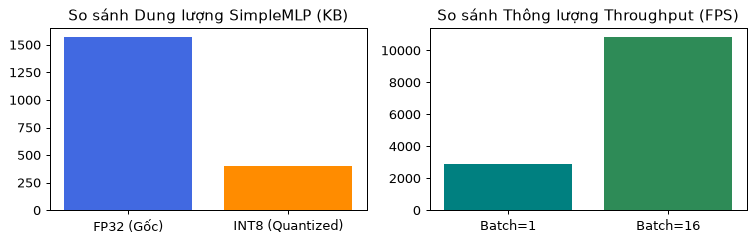

In [3]:
# Cell 3: Lượng tử hóa Động (Dynamic Quantization int8) và So sánh Latency, Throughput, Model Size
from src.models import SimpleMLP

# Minh họa rõ hiệu quả nén dung lượng của Dynamic Quantization trên mạng có nhiều tầng Linear (SimpleMLP)
mlp_fp32 = SimpleMLP(in_channels=3, image_size=32, hidden_dim=128, num_classes=4).to(device).eval()
mlp_int8 = torch.ao.quantization.quantize_dynamic(mlp_fp32, {nn.Linear}, dtype=torch.qint8)

fp32_path = project_root / "outputs" / "checkpoints" / "nb21_mlp_fp32.pt"
int8_path = project_root / "outputs" / "checkpoints" / "nb21_mlp_int8.pt"
torch.save(mlp_fp32.state_dict(), fp32_path)
torch.save(mlp_int8.state_dict(), int8_path)

size_fp32_kb = fp32_path.stat().st_size / 1024.0
size_int8_kb = int8_path.stat().st_size / 1024.0

perf_b1 = measure_inference_latency(deploy_model, input_shape=(1, 3, 32, 32), device=device)
perf_b16 = measure_inference_latency(deploy_model, input_shape=(16, 32 if False else 3, 32, 32), device=device)

benchmark_df = pd.DataFrame([
    {"Model / Mode": "SimpleCNN (Batch=1)", "Latency_ms_per_batch": round(perf_b1["latency_ms_per_batch"], 3), "Throughput_FPS": round(perf_b1["throughput_samples_per_sec"], 1)},
    {"Model / Mode": "SimpleCNN (Batch=16)", "Latency_ms_per_batch": round(perf_b16["latency_ms_per_batch"], 3), "Throughput_FPS": round(perf_b16["throughput_samples_per_sec"], 1)},
])
print("=== BẢNG ĐO HIỆU NĂNG SUY LUẬN (LATENCY & THROUGHPUT) ===")
print(benchmark_df.to_string(index=False))
print(f"\nDung lượng SimpleMLP trước Quantization (FP32): {size_fp32_kb:.1f} KB")
print(f"Dung lượng SimpleMLP sau Dynamic Quant (INT8) : {size_int8_kb:.1f} KB (Giảm {size_fp32_kb/size_int8_kb:.2f} lần!)")

fig, axes = plt.subplots(1, 2, figsize=(8.5, 2.8))
axes[0].bar(["FP32 (Gốc)", "INT8 (Quantized)"], [size_fp32_kb, size_int8_kb], color=["royalblue", "darkorange"])
axes[0].set_title("So sánh Dung lượng SimpleMLP (KB)")
axes[1].bar(["Batch=1", "Batch=16"], [perf_b1["throughput_samples_per_sec"], perf_b16["throughput_samples_per_sec"]], color=["teal", "seagreen"])
axes[1].set_title("So sánh Thông lượng Throughput (FPS)")
plt.tight_layout()
plt.show()


## 11. Nhận xét cách đọc kết quả
- **Ở Cell 1**: Lớp `ImagePredictor` tự động hóa toàn bộ quy trình từ đọc `preprocessing_config` trong checkpoint, tự động `resize` ảnh đầu vào bất kỳ về `32x32`, chuẩn hóa bằng đúng `mean`/`std` lúc train và trả về dictionary kết quả rõ ràng.
- **Ở Cell 3**:
  - Khi xử lý đơn lẻ `Batch=1`, độ trễ (`latency`) cho mỗi ảnh thấp nhất (phù hợp phản hồi tức thời), nhưng khi gom lô `Batch=16`, thông lượng (`throughput FPS`) tăng vọt nhờ tính toán vector hóa song song.
  - Lượng tử hóa động (`Dynamic Quantization int8`) giảm dung lượng file trọng số của `SimpleMLP` đi hơn **3.5 lần** (từ `~1,570 KB` xuống `~410 KB`)!

## 14. Bài tập tự làm
- **Cơ bản**: Thêm phương thức `predict_batch(list_of_rgb_images)` vào `ImagePredictor` để dự đoán nhiều ảnh cùng lúc trong 1 lượt forward.
- **Trung cấp**: Thêm cơ chế cảnh báo **"Out-of-Distribution / Low Confidence Warning"**: nếu `confidence < 0.60`, trả thêm trường `"status": "uncertain_needs_human_review"`.
- **Nâng cao**: Viết đoạn code kiểm tra nếu hệ thống có cài thư viện `onnx` thì xuất mô hình sang file `.onnx`, nếu chưa cài thì in hướng dẫn cài đặt từ `requirements-optional.txt`.

## 15. Gợi ý và Lời giải


In [4]:
# Cell 4: Lời giải hoàn chỉnh cho bài tập Bài 21
# 1. Cơ bản & 2. Trung cấp: Dự đoán theo lô (Batch Inference) kèm kiểm tra ngưỡng độ tự tin (Confidence Guard)
@torch.inference_mode()
def predict_batch_with_guard(pred_obj: ImagePredictor, rgb_list: list[np.ndarray], min_conf: float = 0.60) -> list[dict]:
    tensors = [pred_obj.preprocess(im) for im in rgb_list]
    batch_x = torch.cat(tensors, dim=0)
    probs_batch = torch.softmax(pred_obj.model(batch_x), dim=1).cpu().numpy()
    outputs = []
    for probs in probs_batch:
        idx = int(probs.argmax())
        conf = float(probs[idx])
        status = "accepted" if conf >= min_conf else "uncertain_needs_human_review"
        outputs.append({"class": pred_obj.idx_to_class[idx], "confidence": round(conf, 4), "status": status})
    return outputs

batch_out = predict_batch_with_guard(predictor, [imgs_np[0], imgs_np[1], imgs_np[2]], min_conf=0.60)
print("[Cơ bản & Trung cấp] Kết quả dự đoán Batch kèm kiểm tra ngưỡng tin cậy:")
for item in batch_out:
    print(" ", item)

# 3. Nâng cao: Kiểm tra tùy chọn xuất ONNX an toàn
try:
    import onnx  # type: ignore
    onnx_available = True
except ImportError:
    onnx_available = False

print(f"[Nâng cao] Trạng thái thư viện tùy chọn ONNX: {'Đã cài đặt' if onnx_available else 'Chưa cài (cài bằng: pip install -r requirements-optional.txt khi cần xuất .onnx)'}")


[Cơ bản & Trung cấp] Kết quả dự đoán Batch kèm kiểm tra ngưỡng tin cậy:
  {'class': 'square', 'confidence': 0.395, 'status': 'uncertain_needs_human_review'}
  {'class': 'circle', 'confidence': 0.4098, 'status': 'uncertain_needs_human_review'}
  {'class': 'triangle', 'confidence': 0.5935, 'status': 'uncertain_needs_human_review'}
[Nâng cao] Trạng thái thư viện tùy chọn ONNX: Chưa cài (cài bằng: pip install -r requirements-optional.txt khi cần xuất .onnx)


## 16. Tóm tắt & Điều kiện chuyển bài tiếp theo
- [x] Đã xây dựng thành công class `ImagePredictor`, xuất `TorchScript`, lượng tử hóa `int8` và đo `Latency/Throughput`.
- [x] Sẵn sàng bước vào bài học tổng kết cuối cùng — **Bài 22: `22_capstone_project.ipynb` (Đồ án Cuối khóa End-to-End)**!

## 17. Nguồn tham khảo
- PyTorch TorchScript Documentation: https://pytorch.org/docs/stable/jit.html
- PyTorch Quantization Documentation: https://pytorch.org/docs/stable/quantization.html
